# Controle parental: proteção infantojuvenil no mundo digital
## Aplicação do CRISP-DM a dados públicos (SaferNet e TIC Kids Online Brasil 2025)

| Item | Identificação |
|---|---|
| Instituição | Centro Universitário do Distrito Federal – UDF |
| Disciplina | Ciência de Dados e Aprendizagem de Máquina |
| Docente | Profa. Kadidja Valéria |
| Integrantes | Graziela Marcela Alvarenga Silva Viana; Gabriela Marcela Alvarenga Silva Viana |
| Projeto-base | TCC "Controle parental: proteção infantojuvenil no mundo digital" |
| Metodologia | CRISP-DM (Chapman et al., 2000), seguindo o Guia Prático CRISP-DM da disciplina |

> **Sobre os dados.** Usamos dois tipos de dados e deixamos sempre claro qual é qual.
>
> 1. **Dados reais, mas agregados.** Vêm de publicações da SaferNet Brasil e do Cetic.br/NIC.br. Cada linha tem a fonte e um nível
>    de confiança: `confirmado_texto` quando o número está escrito num texto oficial ou numa matéria, e `leitura_grafico` quando
>    lemos o valor num gráfico do PDF. Essas últimas ainda precisam ser conferidas nas tabelas oficiais antes da entrega.
> 2. **Microdados sintéticos**, 2.400 registros inventados por nós a partir dos percentuais públicos do TIC Kids 2025. Não
>    conseguimos os microdados verdadeiros e precisávamos de mais de 1.000 registros para testar agrupamento e classificação.
>    Eles não são pessoas reais e não provam nada sobre famílias reais (veja `docs/ficha_dados_sinteticos.md`). Tudo que foi feito
>    com eles está marcado como sintético.

**Como seguimos o guia da disciplina.** Em cada fase aparecem o objetivo central, o checklist de execução (o que marcamos como feito)
e a aplicação no projeto, que é o nosso "caso prático".

| Fase | Onde está no notebook |
|---|---|
| 1. Entendimento do negócio | Perguntas P1, P2 e P3, critérios de sucesso, riscos e plano |
| 2. Entendimento dos dados | As seis tabelas, a qualidade e a exploração |
| 3. Preparação dos dados | Índices IMR e IEA, séries e integração |
| 4. Modelagem | Regressão, sensibilidade, K-means e classificação |
| 5. Avaliação | Critérios atingidos ou não, e leitura crítica |
| 6. Implementação | Dashboard, plano de manutenção e lições aprendidas |

## Fase 1 – Entendimento do negócio

**Objetivo central.** Traduzir o problema de negócio em metas técnicas viáveis antes de investir recursos computacionais. No nosso caso o
"negócio" é o TCC: precisamos transformar o problema dele em perguntas que os dados conseguem responder.

**Checklist de execução**

- [x] 1.1 Determinar os objetivos de negócio e os critérios de sucesso
- [x] 1.2 Avaliar a situação (recursos, riscos e custo-benefício)
- [x] 1.3 Determinar as metas técnicas de mineração de dados
- [x] 1.4 Produzir o plano de projeto

### 1.1 Objetivos de negócio e critérios de sucesso

**Problema.** O TCC compara ferramentas de controle parental à luz da LGPD e do ECA Digital. Falta
ligar essa análise ao que os dados nacionais mostram: (i) quanto cresce o problema que as ferramentas
tentam combater e (ii) se a mediação dos responsáveis acompanha o que as crianças e adolescentes fazem
online, em cada idade.

Para isso ficamos com três perguntas:

| Pergunta | Responsável | Técnica | Critério de sucesso |
|---|---|---|---|
| **P1.** A série de denúncias de imagens de abuso e exploração sexual infantil (SaferNet, 2006–2025) pode ser projetada com uma tendência simples? | Graziela | Regressão linear e validação temporal contra modelos-base | Regressão linear com erro médio (MAE) menor que o do modelo ingênuo (ano anterior) |
| **P2.** Em que faixa etária a mediação parental fica atrás da exposição e da autonomia digital? | Gabriela | Índices por faixa etária, regressão linear e análise de sensibilidade | Conclusão que se mantém com definições alternativas dos indicadores |
| **P3.** Com microdados **sintéticos** feitos a partir dos percentuais públicos do TIC Kids 2025, o método consegue (a) agrupar famílias em perfis de mediação e (b) prever quem usa recurso técnico para limitar o tempo na Internet? | Ambas (a definir) | (a) K-means; (b) regressão logística e floresta aleatória, com treino e teste | (a) silhueta de pelo menos 0,20 e diferença de IMR de pelo menos 20 p.p. entre o perfil mais e o menos mediado; (b) AUC no teste de pelo menos 0,60, com o limite inferior do IC95% (bootstrap) acima de 0,55 |

Escrevemos os critérios antes de ver qualquer resultado e não mudamos depois. A P3 testa o método em dados sintéticos e não diz nada
sobre famílias reais.

### 1.2 Avaliação da situação

**Recursos.** Duas pessoas, Python, Jupyter, GitHub e dados públicos gratuitos. Não temos orçamento e não coletamos dados com pessoas.

**Riscos e limites.**

- Os dados são agregados: 20 pontos anuais (P1) e 4 faixas etárias (P2). Não dá para falar de causa nem estimar incerteza com rigor.
- Denúncia mede o que foi reportado, não quantos crimes aconteceram. Ela pode subir porque houve mais crimes ou porque houve mais canais de denúncia.
- Parte dos valores do TIC Kids foi lida de gráficos (coluna `confianca`).
- O TIC Kids 2025 entrevistou 2.370 crianças e adolescentes de 9 a 17 anos e seus responsáveis, entre março e setembro de 2025.
- Dado sintético pode ser confundido com dado real. Para evitar isso, os arquivos começam com `sintetico_`, existe a coluna `sintetico = True`
  e deixamos avisos no notebook e no README.

**Custo-benefício.** O custo é baixo: só dados públicos e nenhum dado pessoal. O ganho é ter números para o capítulo de resultados do TCC
e um código pronto para receber os microdados reais quando conseguirmos o acesso.

**Cuidado ético.** Os dados sintéticos não representam ninguém. Eles vêm só de percentuais públicos, não dá para identificar uma pessoa a
partir deles e os parâmetros que usamos estão descritos em `docs/ficha_dados_sinteticos.md`.

### 1.3 Metas técnicas de mineração de dados

1. Comparar três previsores simples para a série da SaferNet, usando validação com origem móvel.
2. Montar um índice de mediação e um de exposição por faixa etária e ver se a conclusão aguenta definições alternativas.
3. Agrupar os microdados sintéticos em perfis (K-means, com k de 2 a 6, escolhido pela maior silhueta), treinar classificadores
   com divisão 70/30 e medir o quanto o resultado depende das suposições que fizemos ao gerar os dados.

### 1.4 Plano do projeto

| Fase | O que entregamos | Onde |
|---|---|---|
| 1 | Perguntas, critérios, riscos e plano | Este notebook |
| 2 | Seis tabelas em `dados/`, checagem de qualidade e exploração | `scripts/criar_dados.py` e `scripts/criar_dados_sinteticos.py` |
| 3 | Índices IMR e IEA, séries e conferência entre dados agregados e individuais | Este notebook |
| 4 | Modelos de P1, P2 e P3, com o teste de cada um | Este notebook |
| 5 | Tabela de critérios e leitura crítica | Este notebook |
| 6 | Dashboard, plano de manutenção, lições aprendidas e README | `dashboard/` e `README.md` |

### Configuração: rodar no Google Colab ou no computador

Este notebook roda nos dois lugares. No Colab, a célula abaixo baixa o repositório do GitHub e entra na pasta do projeto, para o notebook achar
`dados/` e `scripts/`. No computador, ela não faz nada. As bibliotecas (pandas, scikit-learn, seaborn e matplotlib) já vêm instaladas no Colab.

In [1]:
import os, sys, subprocess

REPO = "https://github.com/alvarengagraziela3-oss/Ciencia_Dados_Aprendizagem_Maquina.git"
PASTA = "Ciencia_Dados_Aprendizagem_Maquina/Projeto_Ciencia_de_dados"

if "google.colab" in sys.modules:                      # só entra aqui quando está no Colab
    if not os.path.exists("Ciencia_Dados_Aprendizagem_Maquina"):
        subprocess.run(["git", "clone", "--depth", "1", REPO], check=True)
    os.chdir(PASTA)
    print("Rodando no Google Colab. Pasta do projeto:", os.getcwd())
else:
    print("Rodando no computador. Pasta atual:", os.getcwd())

Rodando no computador. Pasta atual: /home/claude/proj/notebooks


In [2]:
import warnings; warnings.filterwarnings("ignore")
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import silhouette_score, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DADOS, DASH = RAIZ / "dados", RAIZ / "dashboard"
DASH.mkdir(exist_ok=True)
sys.path.insert(0, str(RAIZ / "scripts"))
from criar_dados_sinteticos import gerar, MED as COLS_MED, EXP as COLS_EXP

SEMENTE = 2025
COLS_IND = COLS_MED + COLS_EXP          # os 6 indicadores usados nos microdados sintéticos

sns.set_theme(style="whitegrid", font_scale=1.0)
COR = {"azul": "#1F4E79", "laranja": "#D9822B", "verde": "#3C8D5A", "cinza": "#8A8F98", "vermelho": "#B23A48"}
milhar = lambda x, _=None: f"{x:,.0f}".replace(",", ".")
pct = lambda x, _=None: f"{x:.0f}%"

## Fase 2 – Entendimento dos dados

**Objetivo central.** Acessar, quantificar e qualificar a matéria-prima disponível para evitar falhas imprevistas na modelagem.

**Checklist de execução**

- [x] 2.1 Coletar os dados iniciais (existentes, comprados ou adicionais)
- [x] 2.2 Descrever quantidade e qualidade (volume, tipos de valores, códigos)
- [x] 2.3 Explorar os dados (gráficos, hipóteses iniciais)
- [x] 2.4 Verificar a qualidade (erros, dados omissos, inconsistências de medição)

### 2.1 Coleta dos dados iniciais

Temos seis tabelas em `dados/`. As quatro primeiras são reais e agregadas e saem do `scripts/criar_dados.py`. As duas últimas são sintéticas
e saem do `scripts/criar_dados_sinteticos.py`. Criamos essas duas porque não conseguimos os microdados do TIC Kids 2025 e a análise por
registro precisa de pelo menos 1.000 linhas.

| Tabela | Origem | Conteúdo | Linhas |
|---|---|---|---:|
| `safernet_csam_2006_2025` | Real | Denúncias novas (links únicos) de imagens de abuso e exploração sexual infantil, por ano | 20 |
| `safernet_tipos_2024_2025` | Real | Denúncias novas por tipo de crime, 2024 e 2025 | 10 |
| `ticKids2025_por_faixa_etaria` | Real | Indicadores de mediação e exposição, por faixa etária | 53 |
| `ticKids2025_totais` | Real | Totais nacionais: acesso, mediação técnica, diálogo, fontes de orientação, riscos | 27 |
| `sintetico_ticKids2025_familias` | Sintética | Registros fictícios: faixa etária, 6 indicadores, uso de recurso técnico e diálogo | 2.400 |
| `sintetico_validacao_marginais` | Sintética | Percentual publicado comparado com o percentual sintético, por indicador e faixa | 26 |

### 2.2 Descrição de quantidade e qualidade

In [3]:
csam  = pd.read_csv(DADOS / "safernet_csam_2006_2025.csv")
tipos = pd.read_csv(DADOS / "safernet_tipos_2024_2025.csv")
faixa = pd.read_csv(DADOS / "ticKids2025_por_faixa_etaria.csv")
tot   = pd.read_csv(DADOS / "ticKids2025_totais.csv")
micro = pd.read_csv(DADOS / "sintetico_ticKids2025_familias.csv")
valid = pd.read_csv(DADOS / "sintetico_validacao_marginais.csv")

for nome, df in [("SaferNet CSAM", csam), ("SaferNet tipos", tipos), ("TIC Kids por faixa", faixa),
                 ("TIC Kids totais", tot), ("SINTÉTICO famílias", micro), ("SINTÉTICO validação", valid)]:
    print(f"{nome:22s} {df.shape[0]:5d} linhas x {df.shape[1]} colunas")
print("\nMicrodados sintéticos: tipos das colunas")
print(micro.dtypes.to_string())
micro.head()

SaferNet CSAM             20 linhas x 3 colunas
SaferNet tipos            10 linhas x 6 colunas
TIC Kids por faixa        53 linhas x 8 colunas
TIC Kids totais           27 linhas x 6 colunas
SINTÉTICO famílias      2400 linhas x 11 colunas
SINTÉTICO validação       26 linhas x 5 colunas

Microdados sintéticos: tipos das colunas
id_sintetico                  str
faixa_etaria                  str
med_regras_celular          int64
med_olha_celular            int64
med_sem_celular             int64
exp_ia_generativa           int64
exp_pesquisou_produtos      int64
exp_compras                 int64
usa_recurso_limite_tempo    int64
conversa_sobre_online       int64
sintetico                    bool


,id_sintetico,faixa_etaria,med_regras_celular,med_olha_celular,med_sem_celular,exp_ia_generativa,exp_pesquisou_produtos,exp_compras,usa_recurso_limite_tempo,conversa_sobre_online,sintetico
0,S0001,9-10,0,1,1,0,0,0,1,1,True
1,S0002,15-17,0,0,0,0,0,0,0,0,True
2,S0003,9-10,1,1,1,1,1,1,1,0,True
3,S0004,15-17,0,0,0,1,1,0,0,0,True
4,S0005,13-14,0,0,0,1,1,1,0,0,True


### 2.3 Exploração dos dados

Nas tabelas reais já dá para ver a hipótese inicial: a mediação restritiva cai com a idade e a exposição sobe. Nos dados sintéticos a
exploração mostra duas coisas. Primeiro, que os percentuais por faixa batem com os publicados (foi assim que o gerador foi feito). Segundo,
a correlação entre os indicadores. Essa correlação não foi descoberta por nós: ela vem de uma suposição do gerador (o parâmetro
`carga_indic`). Na Fase 4 medimos o quanto as conclusões dependem dela.

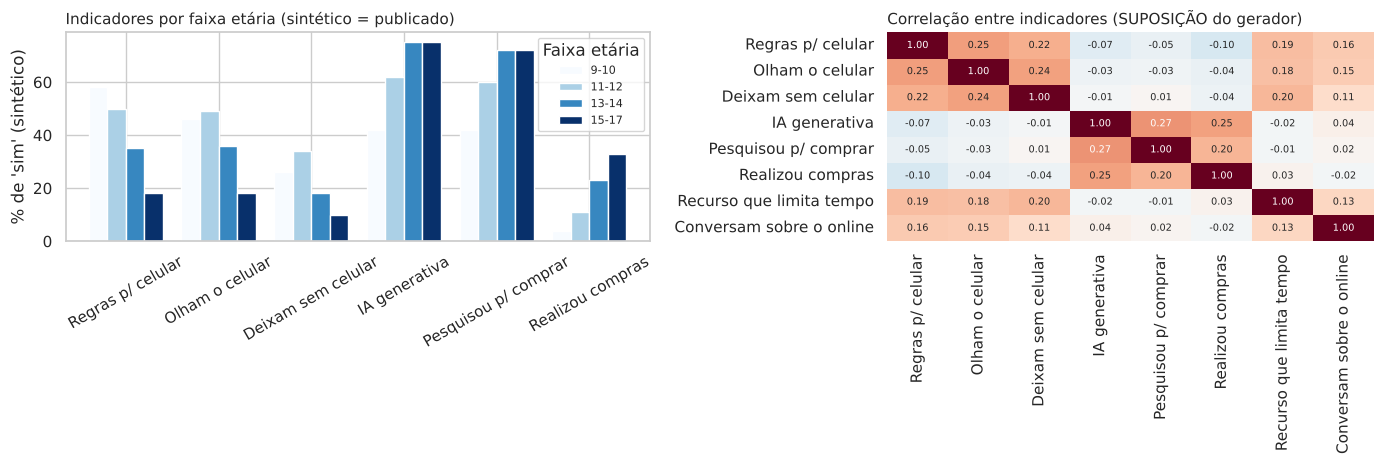

In [4]:
IDADES = ["9-10", "11-12", "13-14", "15-17"]
rotulo = {"med_regras_celular": "Regras p/ celular", "med_olha_celular": "Olham o celular", "med_sem_celular": "Deixam sem celular",
          "exp_ia_generativa": "IA generativa", "exp_pesquisou_produtos": "Pesquisou p/ comprar", "exp_compras": "Realizou compras",
          "usa_recurso_limite_tempo": "Recurso que limita tempo", "conversa_sobre_online": "Conversam sobre o online"}

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
por_faixa = micro.groupby("faixa_etaria")[COLS_IND].mean().loc[IDADES].mul(100).rename(columns=rotulo)
por_faixa.T.plot.bar(ax=ax[0], width=.8, colormap="Blues"); ax[0].set_ylabel("% de 'sim' (sintético)")
ax[0].set_title("Indicadores por faixa etária (sintético = publicado)", loc="left", fontsize=11)
ax[0].legend(title="Faixa etária", fontsize=8); ax[0].tick_params(axis="x", rotation=30)
cor = micro[list(rotulo)].rename(columns=rotulo).corr()
sns.heatmap(cor, ax=ax[1], cmap="RdBu_r", center=0, vmin=-.6, vmax=.6, annot=True, fmt=".2f", annot_kws={"size": 7}, cbar=False)
ax[1].set_title("Correlação entre indicadores (SUPOSIÇÃO do gerador)", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

### 2.4 Verificação da qualidade

In [5]:
# ---- Verificações de qualidade ------------------------------------------------
# 1) série SaferNet completa e sem nulos
assert csam.ano.tolist() == list(range(2006, 2026)), "faltam anos na série"
assert csam.denuncias_novas_csam.notna().all()
print("1) Série SaferNet: 20 anos consecutivos, sem valores ausentes.")

# 2) variação 2024->2025 recalculada confere com a publicada pela SaferNet?
publicada = {"Imagens de abuso e exploração sexual infantil": 19.3, "Intolerância religiosa": 20.0,
             "Neonazismo": 64.7, "Apologia e incitação a crimes contra a vida": 75.4, "Racismo": 58.5,
             "LGBTfobia": 24.3, "Misoginia": 224.9, "Maus tratos contra animais": 53.4,
             "Tráfico de pessoas": 0.9, "Xenofobia": -78.1}
dif = (tipos.set_index("crime").variacao_pct - pd.Series(publicada)).abs()
print(f"2) Maior diferença entre variação recalculada e publicada: {dif.max():.2f} p.p.")
assert dif.max() < 0.2

# 3) percentuais do TIC Kids entre 0 e 100
assert faixa.valor_pct.between(0, 100).all() and tot.valor_pct.between(0, 100).all()
print("3) Todos os percentuais do TIC Kids estão entre 0 e 100.")

# 4) cobertura: quais indicadores têm as 4 faixas etárias?
cob = faixa[faixa.grupo != "Total"].groupby("indicador").grupo.nunique()
print("4) Indicadores sem as 4 faixas (universo 11-17):", cob[cob < 4].index.tolist())

# 5) proveniência dos números do TIC Kids
print("5) Linhas por nível de confiança (por faixa etária):")
print(faixa.confianca.value_counts().to_string())
print("   Linhas por nível de confiança (totais):")
print(tot.confianca.value_counts().to_string())

# 6) divergência entre edições da SaferNet (documentada, não corrigida)
print("6) A edição 2024 da SaferNet traz 25.166 (2011) e 17.443 (2015); a de 2025 traz 25.116 e 17.433.")
print("   Usamos a edição mais recente (2025). A diferença é de 50 e 10 denúncias, sem efeito na análise.")

1) Série SaferNet: 20 anos consecutivos, sem valores ausentes.
2) Maior diferença entre variação recalculada e publicada: 0.00 p.p.
3) Todos os percentuais do TIC Kids estão entre 0 e 100.
4) Indicadores sem as 4 faixas (universo 11-17): ['Gastou em jogos online (itens/fases)', 'Sabe diferenciar conteúdo patrocinado de não patrocinado']
5) Linhas por nível de confiança (por faixa etária):
confianca
confirmado_texto    33
leitura_grafico     20
   Linhas por nível de confiança (totais):
confianca
leitura_grafico     15
confirmado_texto    12
6) A edição 2024 da SaferNet traz 25.166 (2011) e 17.443 (2015); a de 2025 traz 25.116 e 17.433.
   Usamos a edição mais recente (2025). A diferença é de 50 e 10 denúncias, sem efeito na análise.


In [6]:
# ---- Verificações de qualidade dos microdados SINTÉTICOS ------------------------
assert len(micro) >= 1000, "menos de 1.000 registros"
assert micro.id_sintetico.is_unique, "ids repetidos"
assert micro.isna().sum().sum() == 0, "há valores ausentes"
assert set(np.unique(micro[list(rotulo)].values)) <= {0, 1}, "indicadores devem ser 0/1"
assert micro.sintetico.all(), "todo registro deve estar marcado como sintético"
assert set(micro.faixa_etaria) == set(IDADES)
print(f"S1) {milhar(len(micro))} registros, ids únicos, sem valores ausentes, indicadores 0/1, todos marcados como sintéticos.")
print("S2) Registros por faixa etária:", micro.faixa_etaria.value_counts().loc[IDADES].to_dict())

dmax = valid.diferenca_pp.abs().max()
assert dmax <= 0.5
print(f"S3) Maior diferença entre o percentual sintético e o publicado: {dmax:.2f} p.p. (tolerância: 0,5 p.p.).")

nao_ident = [c for c in micro.columns if c not in ["id_sintetico", "faixa_etaria", "sintetico", *rotulo]]
assert not nao_ident
print("S4) Colunas dos microdados:", list(micro.columns), "- sem nome, escola, cidade, contato ou qualquer dado pessoal.")

S1) 2.400 registros, ids únicos, sem valores ausentes, indicadores 0/1, todos marcados como sintéticos.
S2) Registros por faixa etária: {'9-10': 600, '11-12': 600, '13-14': 600, '15-17': 600}
S3) Maior diferença entre o percentual sintético e o publicado: 0.00 p.p. (tolerância: 0,5 p.p.).
S4) Colunas dos microdados: ['id_sintetico', 'faixa_etaria', 'med_regras_celular', 'med_olha_celular', 'med_sem_celular', 'exp_ia_generativa', 'exp_pesquisou_produtos', 'exp_compras', 'usa_recurso_limite_tempo', 'conversa_sobre_online', 'sintetico'] - sem nome, escola, cidade, contato ou qualquer dado pessoal.


**Leitura da qualidade.** A série da SaferNet está completa e a variação que recalculamos bate com a publicada. O ponto fraco é de onde vêm os números:
parte dos valores por faixa etária foi lida de gráficos (coluna `confianca`). Antes de entregar, precisamos conferir essas linhas nas tabelas oficiais
do Cetic.br (cetic.br/pt/tics/kidsonline/2025/). Isso não muda o método, mas pode mexer em um ou dois pontos percentuais em algum valor.

**O que a checagem dos dados sintéticos mostra.** Os percentuais batem com os publicados porque o gerador fixa o número de "sim" de cada
indicador em cada faixa. O que não dá para verificar é a relação entre os indicadores: sem os microdados reais, ela é só uma suposição.
Por isso a Fase 4 tem uma análise de sensibilidade.

## Fase 3 – Preparação dos dados

**Objetivo central.** Transformar, limpar e empacotar dados brutos em um formato digerível pelos algoritmos. É a base do sucesso.

**Checklist de execução**

- [x] 3.1 Selecionar (filtrar): só o universo de 9 a 17 anos e as 4 faixas etárias. Ficam de fora o grupo "Total" e os indicadores com universo de 11 a 17 anos
- [x] 3.2 Limpar (tratar): usar a edição mais recente da SaferNet quando há divergência, conferir que não há valores ausentes e manter os dados sintéticos sem nenhum dado pessoal
- [x] 3.3 Construir (derivar): variação anual, CAGR, índices IMR e IEA (por faixa e por registro), lacuna e faixa etária como número
- [x] 3.4 Integrar (mesclar): conferir os índices dos registros sintéticos contra os índices agregados publicados

**Aplicação no projeto.**

- **P1:** série anual indexada por ano, com variação anual e taxa composta de crescimento (CAGR).
- **P2:** tabela larga (indicador por faixa etária) e dois índices, ambos em pontos percentuais:
  - **Índice de mediação restritiva (IMR):** média de três indicadores. Pais colocam regras para o celular, olham o celular, deixam o filho sem o celular por um tempo.
  - **Índice de exposição e autonomia (IEA):** média de três indicadores. Usou IA generativa, pesquisou produtos para comprar, realizou compras na Internet.
- **P3:** os mesmos IMR e IEA, mas calculados para cada registro sintético, mais a faixa etária como número de 0 a 3.

Os índices são escolhas nossas de modelagem e não medidas oficiais. Por isso a Fase 4 testa a conclusão com definições alternativas.

In [7]:
# ---- P1: série SaferNet ---------------------------------------------------------
s = csam.set_index("ano").denuncias_novas_csam
serie = pd.DataFrame({"denuncias": s, "var_pct": s.pct_change() * 100})
cagr_19_25 = (s[2025] / s[2019]) ** (1 / 6) - 1
print(f"Pico histórico: {s.idxmax()} ({milhar(s.max())}) | 2019: {milhar(s[2019])} | 2025: {milhar(s[2025])}")
print(f"CAGR 2019-2025: {cagr_19_25:.1%} ao ano | 2025 é {s[2025]/s[2019]:.2f}x o nível de 2019")
serie.tail(8).round(1)

Pico histórico: 2023 (71.867) | 2019: 25.518 | 2025: 63.214
CAGR 2019-2025: 16.3% ao ano | 2025 é 2.48x o nível de 2019


,denuncias,var_pct
ano,,
2018,24618,14.6
2019,25518,3.7
2020,46019,80.3
2021,53960,17.3
2022,40572,-24.8
2023,71867,77.1
2024,52999,-26.3
2025,63214,19.3


In [8]:
# ---- P2: tabela larga por faixa etária ------------------------------------------
IDADES = ["9-10", "11-12", "13-14", "15-17"]
MEIO = {"9-10": 9.5, "11-12": 11.5, "13-14": 13.5, "15-17": 16.0}   # ponto médio de cada faixa
larga = (faixa[faixa.grupo.isin(IDADES)]
         .pivot(index="indicador", columns="grupo", values="valor_pct")[IDADES])

MED = ["Pais colocam regras para usar o celular", "Pais olham o celular (com quem fala / o que faz)",
       "Pais deixam sem usar o celular por algum tempo"]
EXP = ["Usou IA generativa (ao menos uma atividade)", "Pesquisou produtos na Internet para comprar",
       "Realizou compras na Internet"]

idx = pd.DataFrame({"IMR (mediação restritiva)": larga.loc[MED].mean(),
                    "IEA (exposição e autonomia)": larga.loc[EXP].mean()})
idx["lacuna_IEA_menos_IMR"] = idx.iloc[:, 1] - idx.iloc[:, 0]
idx.round(1)

,IMR (mediação restritiva),IEA (exposição e autonomia),lacuna_IEA_menos_IMR
grupo,,,
9-10,43.3,29.3,-14.0
11-12,44.3,44.3,0.0
13-14,29.7,56.7,27.0
15-17,15.3,60.0,44.7


In [9]:
# ---- P3: variáveis derivadas nos microdados sintéticos + integração com os índices publicados ----
ORD = {"9-10": 0, "11-12": 1, "13-14": 2, "15-17": 3}
micro["faixa_ord"] = micro.faixa_etaria.map(ORD)
micro["IMR"] = micro[COLS_MED].mean(axis=1) * 100
micro["IEA"] = micro[COLS_EXP].mean(axis=1) * 100
micro["lacuna"] = micro.IEA - micro.IMR

integra = micro.groupby("faixa_etaria")[["IMR", "IEA"]].mean().loc[IDADES]
integra.columns = ["IMR sintético", "IEA sintético"]
integra["IMR publicado"] = idx.iloc[:, 0].round(1).values
integra["IEA publicado"] = idx.iloc[:, 1].round(1).values
assert (integra["IMR sintético"] - integra["IMR publicado"]).abs().max() < 0.5
assert (integra["IEA sintético"] - integra["IEA publicado"]).abs().max() < 0.5
print("Índices individuais (média por faixa) × índices agregados publicados: diferença < 0,5 p.p. nas 4 faixas.")
integra.round(1)

Índices individuais (média por faixa) × índices agregados publicados: diferença < 0,5 p.p. nas 4 faixas.


,IMR sintético,IEA sintético,IMR publicado,IEA publicado
faixa_etaria,,,,
9-10,43.3,29.3,43.3,29.3
11-12,44.3,44.3,44.3,44.3
13-14,29.7,56.7,29.7,56.7
15-17,15.3,60.0,15.3,60.0


## Fase 4 – Modelagem

**Objetivo central.** Aplicar técnicas matemáticas, gerar designs de teste e iterar parâmetros para descobrir padrões de alto valor.

**Checklist de execução**

- [x] 4.1 Selecionar técnicas (clusterização, predição)
- [x] 4.2 Gerar o design de teste (partição em treino e teste)
- [x] 4.3 Construir e iterar (parâmetros e análise de sensibilidade)
- [x] 4.4 Fazer a avaliação técnica estatística (MAE, AUC, intervalo de confiança)

| Pergunta | Técnica | Como testamos |
|---|---|---|
| P1 | Regressão linear, média de 3 anos e modelo ingênuo | Origem móvel: para cada ano de 2012 a 2025 o modelo só enxerga o passado |
| P2 | Índices IMR e IEA, regressão linear sobre a idade e sensibilidade nos 9 pares | Só descritivo (n = 4). Para ver se a conclusão aguenta, usamos definições alternativas dos indicadores |
| P3 (a) | K-means com os 6 indicadores | k de 2 a 6, escolhido pela silhueta. Não precisa de treino e teste porque não tem resposta certa |
| P3 (b) | Regressão logística e floresta aleatória, contra um modelo-base | Divisão 70/30 estratificada. O modelo é escolhido por validação cruzada (5 partes) usando só o treino, e o teste é usado uma única vez |

### P1 · A série da SaferNet pode ser projetada com uma tendência simples?

Comparamos três previsores de um passo à frente, avaliados com origem móvel (para cada ano de 2012 a 2025,
o modelo só enxerga os anos anteriores):

1. **Ingênuo:** repete o valor do ano anterior. É o modelo-base.
2. **Média móvel de 3 anos.**
3. **Tendência linear:** regressão linear nos 5 anos anteriores (`LinearRegression`).

Medimos o erro médio absoluto (MAE) e o erro percentual médio absoluto (MAPE).

In [10]:
linhas = []
for t in range(2012, 2026):
    hist = s[s.index < t]
    h5 = hist.iloc[-5:]
    lr = LinearRegression().fit(h5.index.values.reshape(-1, 1), h5.values)
    linhas.append(dict(ano=t, real=s[t],
                       ingenuo=hist.iloc[-1],
                       media3=hist.iloc[-3:].mean(),
                       tendencia5=lr.predict([[t]])[0]))
bt = pd.DataFrame(linhas).set_index("ano")

metodos = ["ingenuo", "media3", "tendencia5"]
aval = pd.DataFrame({
    "MAE": [(bt.real - bt[m]).abs().mean() for m in metodos],
    "MAPE_%": [((bt.real - bt[m]).abs() / bt.real).mean() * 100 for m in metodos],
}, index=metodos).round(1)
aval["MAE_vs_ingenuo_%"] = ((aval.MAE / aval.loc["ingenuo", "MAE"] - 1) * 100).round(1)
print("Validação com origem móvel, 2012-2025 (14 previsões por método)")
aval

Validação com origem móvel, 2012-2025 (14 previsões por método)


,MAE,MAPE_%,MAE_vs_ingenuo_%
ingenuo,8558.3,19.4,0.0
media3,8407.8,22.4,-1.8
tendencia5,8685.2,23.6,1.5


In [11]:
# ---- tendência recente (2019-2025): regressão log-linear -------------------------
rec = s[s.index >= 2019]
X = rec.index.values.reshape(-1, 1)
lr_log = LinearRegression().fit(X, np.log(rec.values))
r2 = lr_log.score(X, np.log(rec.values))
cresc = np.exp(lr_log.coef_[0]) - 1
print(f"Tendência 2019-2025 (log-linear): {cresc:.1%} ao ano | R² = {r2:.2f} | n = {len(rec)}")

# ---- faixa indicativa para 2026 (NÃO é previsão confiável) ------------------------
hist = s
h5 = hist.iloc[-5:]
lr5 = LinearRegression().fit(h5.index.values.reshape(-1, 1), h5.values)
cand = {"ingenuo": hist.iloc[-1], "media3": hist.iloc[-3:].mean(), "tendencia5": lr5.predict([[2026]])[0]}
mae = aval.MAE.min()
print("Valores de 2026 pelos três métodos:", {k: milhar(v) for k, v in cand.items()})
print(f"Faixa dos métodos: {milhar(min(cand.values()))} a {milhar(max(cand.values()))} | erro típico (MAE) ≈ {milhar(mae)}")

Tendência 2019-2025 (log-linear): 12.5% ao ano | R² = 0.56 | n = 7
Valores de 2026 pelos três métodos: {'ingenuo': '63.214', 'media3': '62.693', 'tendencia5': '65.803'}
Faixa dos métodos: 62.693 a 65.803 | erro típico (MAE) ≈ 8.408


### P2 · Onde a mediação fica atrás da exposição?

Fizemos duas análises. Na primeira, olhamos como cada índice muda com a idade, usando uma regressão linear sobre o ponto médio de cada faixa
(n = 4, então só serve para descrever, sem teste de significância). Na segunda, a análise de sensibilidade, cruzamos cada indicador de mediação com
cada indicador de exposição e vimos qual é a primeira faixa etária em que a exposição passa a mediação.

In [12]:
# (a) inclinação de cada índice por ano de idade (descritivo, n = 4)
xs = np.array([MEIO[i] for i in IDADES]).reshape(-1, 1)
for col in ["IMR (mediação restritiva)", "IEA (exposição e autonomia)"]:
    m = LinearRegression().fit(xs, idx[col].values)
    print(f"{col:30s} inclinação = {m.coef_[0]:+.1f} p.p. por ano de idade | R² = {m.score(xs, idx[col].values):.2f}")

# (b) sensibilidade: exposição - mediação, para cada par de indicadores
curto = lambda t: (t.replace("Pais colocam regras para usar o celular", "Regras p/ celular")
                    .replace("Pais olham o celular (com quem fala / o que faz)", "Olham o celular")
                    .replace("Pais deixam sem usar o celular por algum tempo", "Deixam sem celular")
                    .replace("Usou IA generativa (ao menos uma atividade)", "IA generativa")
                    .replace("Pesquisou produtos na Internet para comprar", "Pesquisou p/ comprar")
                    .replace("Realizou compras na Internet", "Realizou compras"))
linhas, primeira = [], []
for m_ in MED:
    for e_ in EXP:
        d = larga.loc[e_] - larga.loc[m_]
        linhas.append(pd.Series(d.values, index=IDADES, name=f"{curto(e_)} − {curto(m_)}"))
        cruza = [i for i in IDADES if d[i] > 0]
        primeira.append(cruza[0] if cruza else "nenhuma")
sens = pd.DataFrame(linhas)
sens["1ª faixa em que exposição > mediação"] = primeira
print("\nSensibilidade (pontos percentuais; positivo = exposição maior que mediação)")
sens

IMR (mediação restritiva)      inclinação = -4.6 p.p. por ano de idade | R² = 0.89
IEA (exposição e autonomia)    inclinação = +4.8 p.p. por ano de idade | R² = 0.91

Sensibilidade (pontos percentuais; positivo = exposição maior que mediação)


,9-10,11-12,13-14,15-17,1ª faixa em que exposição > mediação
IA generativa − Regras p/ celular,-16.0,12.0,40.0,57.0,11-12
Pesquisou p/ comprar − Regras p/ celular,-16.0,10.0,37.0,54.0,11-12
Realizou compras − Regras p/ celular,-54.0,-39.0,-12.0,15.0,15-17
IA generativa − Olham o celular,-4.0,13.0,39.0,57.0,11-12
Pesquisou p/ comprar − Olham o celular,-4.0,11.0,36.0,54.0,11-12
Realizou compras − Olham o celular,-42.0,-38.0,-13.0,15.0,15-17
IA generativa − Deixam sem celular,16.0,28.0,57.0,65.0,9-10
Pesquisou p/ comprar − Deixam sem celular,16.0,26.0,54.0,62.0,9-10
Realizou compras − Deixam sem celular,-22.0,-23.0,5.0,23.0,13-14


In [13]:
print("Faixa em que a exposição passa a superar a mediação, nos 9 pares de indicadores:")
print(sens["1ª faixa em que exposição > mediação"].value_counts().to_string())
print("\nIMR e IEA se cruzam em:", idx.index[idx['lacuna_IEA_menos_IMR'] >= 0][0] if (idx['lacuna_IEA_menos_IMR'] >= 0).any() else "nenhuma faixa")

Faixa em que a exposição passa a superar a mediação, nos 9 pares de indicadores:
1ª faixa em que exposição > mediação
11-12    4
15-17    2
9-10     2
13-14    1

IMR e IEA se cruzam em: 11-12


### P3 · Perfis de mediação e previsão do uso de recurso técnico (microdados SINTÉTICOS)

> **Atenção: dados sintéticos.** O que está abaixo mostra se o método consegue recuperar a estrutura que nós colocamos nos dados. Não é
> resultado sobre famílias reais. Os percentuais por faixa etária vêm das tabelas públicas, mas a relação entre os indicadores é suposição nossa.

**(a) Perfis.** K-means com os 6 indicadores de mediação e exposição, com k de 2 a 6 e escolha pela maior silhueta (a regra que definimos na Fase 1).
Chamamos os perfis de A a F, do mais mediado para o menos mediado, para não confundir com as perguntas P1 a P3.

In [14]:
X_cl = micro[COLS_IND].values
sil = {k: silhouette_score(X_cl, KMeans(n_clusters=k, n_init=10, random_state=SEMENTE).fit(X_cl).labels_) for k in range(2, 7)}
K_BEST = max(sil, key=sil.get)
print("Silhueta por k:", {k: round(v, 3) for k, v in sil.items()}, "->  k escolhido =", K_BEST)

micro["perfil_num"] = KMeans(n_clusters=K_BEST, n_init=10, random_state=SEMENTE).fit_predict(X_cl)
ordem = micro.groupby("perfil_num").IMR.mean().sort_values(ascending=False).index        # do mais ao menos mediado
letras = {num: "ABCDEF"[i] for i, num in enumerate(ordem)}
micro["perfil"] = micro.perfil_num.map(letras)

perfis = micro.groupby("perfil").agg(registros=("id_sintetico", "size"), IMR=("IMR", "mean"), IEA=("IEA", "mean"),
                                     faixa_media=("faixa_ord", "mean"))
perfis["% do total"] = perfis.registros / len(micro) * 100
comp_idade = pd.crosstab(micro.perfil, micro.faixa_etaria, normalize="index").loc[:, IDADES].mul(100)
comp_idade.columns = [f"% {c}" for c in IDADES]
print(f"\nDiferença de IMR entre o perfil mais e o menos mediado: {perfis.IMR.max() - perfis.IMR.min():.1f} p.p.")
display(pd.concat([perfis, comp_idade], axis=1).round(1))

ind_perfil = micro.groupby("perfil")[COLS_IND].mean().mul(100).rename(columns=rotulo)
ind_perfil.round(0)

Silhueta por k: {2: 0.242, 3: 0.252, 4: 0.266, 5: 0.272, 6: 0.323} ->  k escolhido = 6

Diferença de IMR entre o perfil mais e o menos mediado: 77.1 p.p.


,registros,IMR,IEA,faixa_media,% do total,% 9-10,% 11-12,% 13-14,% 15-17
perfil,,,,,,,,,
A,335,87.5,44.7,1.0,14.0,34.0,41.2,17.6,7.2
B,497,48.0,59.0,1.3,20.7,28.4,26.6,28.4,16.7
C,440,29.8,1.1,0.9,18.3,48.4,23.9,14.3,13.4
D,254,14.2,97.5,2.3,10.6,3.5,11.0,33.5,52.0
E,265,13.0,38.6,1.8,11.0,14.3,25.3,26.4,34.0
F,609,10.3,56.5,1.9,25.4,14.0,21.3,29.9,34.8


,Regras p/ celular,Olham o celular,Deixam sem celular,IA generativa,Pesquisou p/ comprar,Realizou compras
perfil,,,,,,
A,84.0,93.0,85.0,49.0,75.0,10.0
B,100.0,34.0,10.0,88.0,73.0,16.0
C,41.0,35.0,14.0,0.0,0.0,3.0
D,4.0,23.0,15.0,93.0,100.0,100.0
E,0.0,26.0,13.0,100.0,0.0,16.0
F,0.0,22.0,9.0,70.0,100.0,0.0


**(b) Previsão.** A variável que queremos prever é `usa_recurso_limite_tempo` (37% dos responsáveis, total nacional publicado). Usamos a faixa
etária e os 6 indicadores. Dividimos os dados em 70% para treino e 30% para teste, mantendo a proporção de faixa e de resposta. O modelo é
escolhido pela AUC em validação cruzada de 5 partes, usando só o treino, e o teste entra uma única vez. O modelo-base só repete a prevalência
(AUC 0,50). O IC95% da AUC vem de 1.000 reamostragens (bootstrap).

In [15]:
FEAT = ["faixa_ord"] + COLS_IND
y = micro.usa_recurso_limite_tempo
estrato = micro.faixa_etaria + "_" + y.astype(str)
Xtr, Xte, ytr, yte = train_test_split(micro[FEAT], y, test_size=0.30, stratify=estrato, random_state=SEMENTE)
print(f"Treino: {len(Xtr)} registros | Teste: {len(Xte)} registros | % com recurso técnico: treino {ytr.mean():.1%}, teste {yte.mean():.1%}")

modelos = {"base (prevalência)": DummyClassifier(strategy="prior"),
           "regressão logística": LogisticRegression(max_iter=1000),
           "floresta aleatória": RandomForestClassifier(n_estimators=300, max_depth=5, random_state=SEMENTE)}
cv = StratifiedKFold(5, shuffle=True, random_state=SEMENTE)
cv_auc = {n: cross_val_score(m, Xtr, ytr, cv=cv, scoring="roc_auc").mean() for n, m in modelos.items()}
escolhido = max((n for n in cv_auc if not n.startswith("base")), key=cv_auc.get)

def ic_auc(y_true, p, n=1000, seed=SEMENTE):
    rng = np.random.default_rng(seed); y_true = np.asarray(y_true); aucs = []
    for _ in range(n):
        i = rng.integers(0, len(y_true), len(y_true))
        if y_true[i].min() != y_true[i].max():
            aucs.append(roc_auc_score(y_true[i], p[i]))
    return np.percentile(aucs, [2.5, 97.5])

linhas = []
for n, m in modelos.items():
    m.fit(Xtr, ytr)
    p = m.predict_proba(Xte)[:, 1]
    lo, hi = ic_auc(yte, p) if n == escolhido else (np.nan, np.nan)
    linhas.append(dict(modelo=n, AUC_validacao_cruzada=cv_auc[n], AUC_teste=roc_auc_score(yte, p), IC95_inferior=lo, IC95_superior=hi))
res_clf = pd.DataFrame(linhas).set_index("modelo").round(3)
print("Modelo escolhido pela validação cruzada (só treino):", escolhido)
modelo_final = modelos[escolhido]
p_te = modelo_final.predict_proba(Xte)[:, 1]
auc_te = roc_auc_score(yte, p_te)
ic_lo, ic_hi = ic_auc(yte, p_te)
res_clf

Treino: 1680 registros | Teste: 720 registros | % com recurso técnico: treino 36.9%, teste 37.2%


Modelo escolhido pela validação cruzada (só treino): floresta aleatória


,AUC_validacao_cruzada,AUC_teste,IC95_inferior,IC95_superior
modelo,,,,
base (prevalência),0.500,0.500,NaN,NaN
regressão logística,0.653,0.673,NaN,NaN
floresta aleatória,0.656,0.661,0.62,0.702


In [16]:
# quais variáveis o modelo usa? (importância na floresta; coeficientes padronizados na logística)
if escolhido == "floresta aleatória":
    imp = pd.Series(modelo_final.feature_importances_, index=FEAT)
else:
    imp = pd.Series(np.abs(modelo_final.coef_[0]), index=FEAT)
imp = (imp / imp.sum() * 100).rename(index=rotulo | {"faixa_ord": "Faixa etária"}).sort_values(ascending=False)
print("Importância relativa das variáveis (%):")
imp.round(1)

Importância relativa das variáveis (%):


Regras p/ celular       24.3
Olham o celular         23.2
Deixam sem celular      19.3
Faixa etária            16.0
Realizou compras         7.1
IA generativa            5.3
Pesquisou p/ comprar     4.8
dtype: float64

**(c) Sensibilidade.** Quanto o resultado de P3 depende do que nós supusemos ao gerar os dados? Repetimos tudo com 3 sementes e mudando as duas
suposições: `carga_indic` (o quanto os indicadores do mesmo tipo andam juntos) e `carga_recurso` (o quanto o uso de recurso técnico anda com a
mediação). Os percentuais por faixa etária continuam iguais aos publicados em todos os casos.

In [17]:
grade = []
for ci in [0.3, 0.6, 0.9]:
    for cr in [0.0, 0.3, 0.6, 0.9]:
        aucs, sils = [], []
        for sd in [1, 2, 3]:
            d = gerar(semente=sd, carga_indic=ci, carga_recurso=cr)
            d["faixa_ord"] = d.faixa_etaria.map(ORD)
            yy = d.usa_recurso_limite_tempo
            xtr, xte, ytr_, yte_ = train_test_split(d[FEAT], yy, test_size=0.30, stratify=d.faixa_etaria + "_" + yy.astype(str), random_state=sd)
            lr = LogisticRegression(max_iter=1000).fit(xtr, ytr_)
            aucs.append(roc_auc_score(yte_, lr.predict_proba(xte)[:, 1]))
            Xd = d[COLS_IND].values
            sils.append(silhouette_score(Xd, KMeans(n_clusters=K_BEST, n_init=10, random_state=sd).fit(Xd).labels_))
        grade.append(dict(carga_indic=ci, carga_recurso=cr, AUC_teste=np.mean(aucs), silhueta=np.mean(sils)))
grade = pd.DataFrame(grade)
tab_auc = grade.pivot(index="carga_indic", columns="carga_recurso", values="AUC_teste")
tab_sil = grade.groupby("carga_indic").silhueta.mean()
print("AUC no teste (regressão logística, média de 3 sementes). Linhas: carga_indic | colunas: carga_recurso")
display(tab_auc.round(2))
print("Silhueta (k fixo no valor escolhido), por carga_indic:")
tab_sil.round(2).to_frame("silhueta")

AUC no teste (regressão logística, média de 3 sementes). Linhas: carga_indic | colunas: carga_recurso


carga_recurso,0.0,0.3,0.6,0.9
carga_indic,,,,
0.3,0.49,0.55,0.60,0.65
0.6,0.52,0.60,0.68,0.79
0.9,0.52,0.62,0.72,0.87


Silhueta (k fixo no valor escolhido), por carga_indic:


,silhueta
carga_indic,
0.3,0.29
0.6,0.33
0.9,0.50


## Fase 5 – Avaliação

**Objetivo central.** Medir a eficácia dos modelos finais exclusivamente através da lente dos critérios de sucesso do negócio definidos na Fase 1.
Como o guia diz, impacto real vale mais que precisão técnica: de nada adianta um erro pequeno se a conclusão não ajuda o TCC.

**Checklist de execução**

- [x] 5.1 Avaliar se os resultados respondem à meta
- [x] 5.2 Revisar falhas no processo
- [x] 5.3 Determinar: implementar ou iterar?

### 5.1 Os resultados respondem à meta?

Comparamos os resultados com os critérios da Fase 1. A tabela abaixo é montada a partir dos números calculados.

In [18]:
melhor = aval.MAE.idxmin()
ganho = -aval.loc[melhor, "MAE_vs_ingenuo_%"]
p1_ok = (aval.loc["tendencia5", "MAE"] < aval.loc["ingenuo", "MAE"])
fx = sens["1ª faixa em que exposição > mediação"].value_counts()
dominante = fx.idxmax()
p2_ok = fx.max() >= 5          # a mesma faixa aparece em pelo menos 5 dos 9 pares
dif_imr = perfis.IMR.max() - perfis.IMR.min()
p3a_ok = (sil[K_BEST] >= 0.20) and (dif_imr >= 20)
p3b_ok = (auc_te >= 0.60) and (ic_lo > 0.55)

av = pd.DataFrame([
    ["P1", "Tendência linear com MAE menor que o modelo ingênuo",
     f"MAE ingênuo {milhar(aval.loc['ingenuo','MAE'])} | média 3 anos {milhar(aval.loc['media3','MAE'])} | tendência {milhar(aval.loc['tendencia5','MAE'])}",
     "Atendido" if p1_ok else "Não atendido"],
    ["P2", "Mesma faixa etária em pelo menos 5 dos 9 pares de indicadores",
     f"Faixa mais frequente: {dominante} ({fx.max()} de 9 pares)",
     "Atendido" if p2_ok else "Não atendido"],
    ["P3a (sintético)", "Silhueta ≥ 0,20 e diferença de IMR ≥ 20 p.p. entre perfis",
     f"Silhueta {sil[K_BEST]:.2f} (k = {K_BEST}) | diferença de IMR {dif_imr:.0f} p.p.",
     "Atendido" if p3a_ok else "Não atendido"],
    ["P3b (sintético)", "AUC no teste ≥ 0,60 e limite inferior do IC95% > 0,55",
     f"{escolhido}: AUC {auc_te:.2f} (IC95% {ic_lo:.2f} a {ic_hi:.2f})",
     "Atendido" if p3b_ok else "Não atendido"],
], columns=["Pergunta", "Critério de sucesso", "Resultado", "Situação"])
display(av)

# Conclusões mais fracas, verificadas nos mesmos 9 pares (não substituem o critério acima)
g = sens[IDADES]
print("\nVerificações complementares do P2 (9 pares de indicadores):")
print(f" - exposição > mediação aos 15-17 anos em {(g['15-17'] > 0).sum()} de 9 pares")
print(f" - lacuna maior aos 15-17 do que aos 9-10 em {(g['15-17'] > g['9-10']).sum()} de 9 pares")
print(f" - lacuna crescente em todas as faixas, em {(g.diff(axis=1).iloc[:, 1:] > 0).all(axis=1).sum()} de 9 pares")
print(f" - exposição > mediação já aos 9-10 anos em {(g['9-10'] > 0).sum()} de 9 pares")
print(f"\nVerificação complementar do P3b: AUC da regressão logística varia de {tab_auc.values.min():.2f} a {tab_auc.values.max():.2f} "
      f"conforme as suposições do gerador (grade da Fase 4).")

,Pergunta,Critério de sucesso,Resultado,Situação
0,P1,Tendência linear com MAE menor que o modelo in...,MAE ingênuo 8.558 | média 3 anos 8.408 | tendê...,Não atendido
1,P2,Mesma faixa etária em pelo menos 5 dos 9 pares...,Faixa mais frequente: 11-12 (4 de 9 pares),Não atendido
2,P3a (sintético),"Silhueta ≥ 0,20 e diferença de IMR ≥ 20 p.p. e...",Silhueta 0.32 (k = 6) | diferença de IMR 77 p.p.,Atendido
3,P3b (sintético),"AUC no teste ≥ 0,60 e limite inferior do IC95%...",floresta aleatória: AUC 0.66 (IC95% 0.62 a 0.70),Atendido



Verificações complementares do P2 (9 pares de indicadores):
 - exposição > mediação aos 15-17 anos em 9 de 9 pares
 - lacuna maior aos 15-17 do que aos 9-10 em 9 de 9 pares
 - lacuna crescente em todas as faixas, em 8 de 9 pares
 - exposição > mediação já aos 9-10 anos em 2 de 9 pares

Verificação complementar do P3b: AUC da regressão logística varia de 0.49 a 0.87 conforme as suposições do gerador (grade da Fase 4).


**Leitura crítica.**

- **P1: critério não atingido.** Os três previsores empataram com o modelo ingênuo, com erro de 8,4 a 8,7 mil denúncias por ano. A média de 3 anos
  errou 1,8% a menos, mas o MAPE dela foi pior (22,4% contra 19,4%), e a tendência linear errou 1,5% a mais. Diferenças tão pequenas não separam
  os métodos. A série tem muitos saltos (pandemia, mudanças nos canais de denúncia e, segundo a própria SaferNet, o uso de IA para produzir
  conteúdo) e não segue uma tendência suave. Por isso a regressão descreve o crescimento recente (cerca de 12% ao ano entre 2019 e 2025, R² de 0,56 com
  só 7 pontos), mas não serve para projetar 2026. A faixa de 62 a 66 mil denúncias é só uma referência, com erro típico de uns 8 mil.
- **P2: critério não atingido.** A faixa etária em que a exposição passa a mediação depende dos indicadores escolhidos. A mais frequente é a de 11 a 12 anos
  (4 de 9 pares), mas vai de 9–10 (quando a mediação é medida por "deixam sem celular") até 15–17 (quando a exposição é medida por compras de verdade).
  Então um ponto de corte único não se sustenta. O que se mantém nos 9 pares (verificações acima) é que aos 15–17 anos a exposição supera a mediação
  em todos eles, e que a lacuna aos 15–17 é maior que aos 9–10. Os dois índices se cruzam aos 11–12 anos. O IMR cai cerca de 4,6 p.p. por ano de idade
  e o IEA sobe cerca de 4,8 p.p. (só descritivo, n = 4).
- **P3: critérios atingidos, mas com ressalva (dados sintéticos).** (a) O K-means escolheu k = 6 (silhueta 0,32). Os perfis vão de famílias muito
  mediadas (perfil A, IMR 88) a pouco mediadas (perfil F, IMR 10), uma diferença de 77 p.p. Só que a silhueta sempre cresce com o k e o k escolhido
  é o limite do intervalo que testamos (veja 5.2). (b) A floresta aleatória teve AUC de 0,66 no teste (IC95% de 0,62 a 0,70), acima do modelo-base (0,50).
  As três variáveis de mediação somam cerca de 67% da importância, o que já era esperado, porque o gerador liga o recurso técnico à mediação. A ressalva
  principal é que, na análise de sensibilidade, a AUC vai de 0,49 a 0,87 conforme a suposição do gerador, e fica perto de 0,5 (sem sinal nenhum) quando o
  recurso técnico não tem ligação com a mediação. Ou seja, o critério foi atingido porque a estrutura foi colocada nos dados. Com microdados reais o resultado pode ser outro.
- **Limites.** Dados agregados, 4 faixas etárias, indicadores lidos de gráfico e denúncias que medem reporte, não ocorrência. Não afirmamos causalidade.
  Os microdados sintéticos repetem, por construção, os percentuais publicados, então não trazem nenhuma conclusão nova sobre P1 ou P2.

**Nova pergunta que a avaliação levanta (volta às Fases 2 e 3).** Agrupar famílias por perfil de mediação (K-means) e prever quais não usam nenhum
recurso técnico foi testado aqui só com dados sintéticos (P3). Para responder isso de verdade, precisamos pedir o acesso aos microdados ao Cetic.br.

### 5.2 Revisão do processo (o que não deu certo ou ficou fraco)

- Os critérios de P1 e P2 não foram atingidos. Mantivemos os critérios como estavam, sem afrouxar depois de ver os dados.
- Parte dos valores do TIC Kids foi lida de gráficos e ainda precisa de conferência nas tabelas oficiais.
- Na P3, a regra "maior silhueta entre k = 2 e 6" escolheu o limite de cima do intervalo. Com dados de sim ou não e poucas combinações possíveis, a silhueta
  tende a crescer com o k. Por isso os perfis devem ser lidos como um resumo descritivo e não como grupos que existem de verdade.
- Parte do desempenho da P3b vem das suposições do gerador, como a grade de sensibilidade mostra. O resultado vale como teste do método.

### 5.3 Decisão: implementar ou iterar?

**Iterar.** (1) P1: não usar projeção no TCC e usar a série só de forma descritiva. (2) P2: usar como argumento descritivo que, aos 15–17 anos, a exposição supera
a mediação, o que apoia a ideia de que as ferramentas precisam se adaptar à idade. (3) P3: deixar o código pronto e rodar de novo com os microdados reais assim que
tivermos acesso, trocando o arquivo `dados/sintetico_ticKids2025_familias.csv`. (4) Conferir as linhas `leitura_grafico`.

## Fase 6 – Implementação e dashboard

**Objetivo central.** Incorporar formalmente os modelos ao sistema da empresa ou utilizar as descobertas para mudar a estratégia. Para nós, o "sistema" é o
repositório do projeto e a "estratégia" é o capítulo de resultados do TCC.

**Entregáveis finais**

- [x] 6.1 Plano de implementação (arquitetura)
- [x] 6.2 Plano de monitoramento (obsolescência do modelo)
- [x] 6.3 Relatório e apresentação final
- [x] 6.4 Revisão do projeto (lições aprendidas)

### Dashboard (parte do 6.3)

O dashboard é feito em Python (Pandas, Matplotlib e Seaborn) e salvo em `dashboard/`, em quatro páginas. A página 4 usa dados sintéticos e
tem esse aviso escrito na própria imagem.

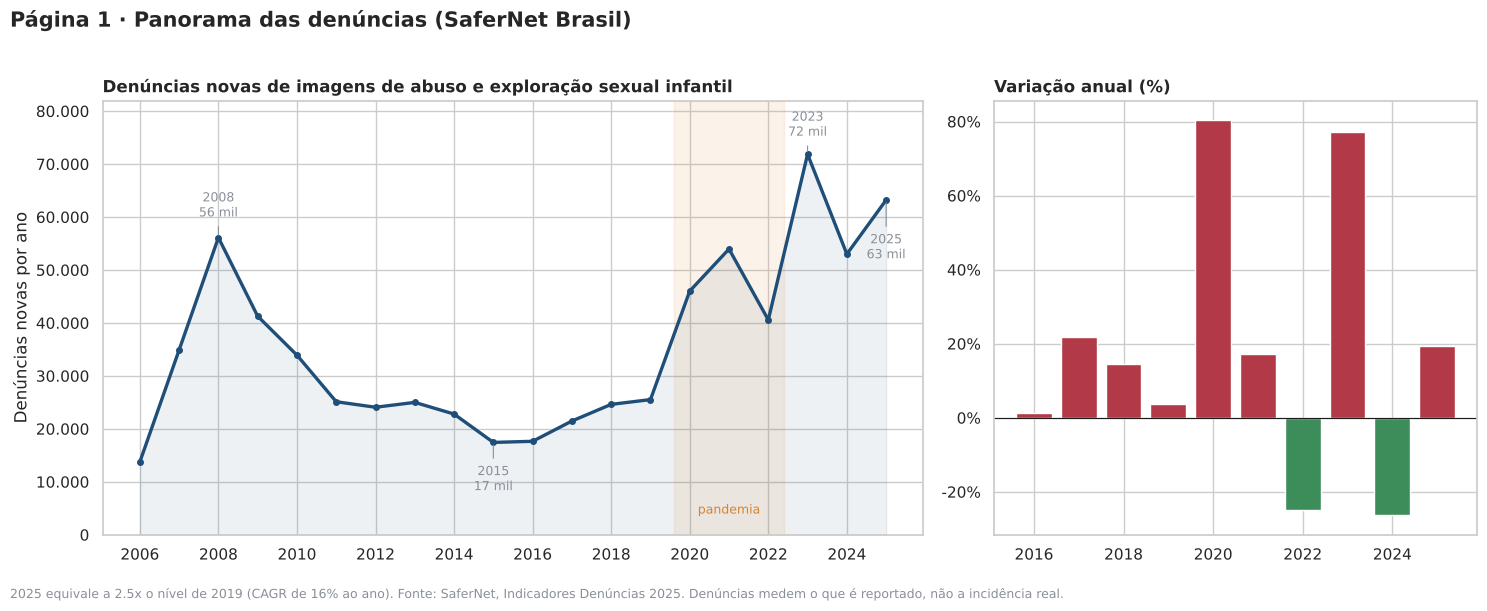

In [19]:
# ===================== Página 1 – Série SaferNet ===================================
fig, ax = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1.7, 1]})
a = ax[0]
a.plot(s.index, s.values, color=COR["azul"], lw=2.4, marker="o", ms=4)
a.fill_between(s.index, s.values, color=COR["azul"], alpha=.08)
for ano, txt, dy in [(2008, "2008\n56 mil", 4000), (2015, "2015\n17 mil", -9000), (2023, "2023\n72 mil", 3500), (2025, "2025\n63 mil", -11000)]:
    a.annotate(txt, (ano, s[ano]), xytext=(ano, s[ano] + dy), ha="center", fontsize=9, color=COR["cinza"],
               arrowprops=dict(arrowstyle="-", color=COR["cinza"], lw=.8))
a.axvspan(2019.6, 2022.4, color=COR["laranja"], alpha=.10)
a.text(2021, 4000, "pandemia", ha="center", color=COR["laranja"], fontsize=9)
a.set_title("Denúncias novas de imagens de abuso e exploração sexual infantil", loc="left", fontweight="bold")
a.set_ylabel("Denúncias novas por ano"); a.yaxis.set_major_formatter(mt.FuncFormatter(milhar))
a.set_xticks(range(2006, 2026, 2)); a.set_ylim(0, 82000)

b = ax[1]
v = serie.var_pct.loc[2016:]
b.bar(v.index, v.values, color=[COR["vermelho"] if x > 0 else COR["verde"] for x in v.values])
b.axhline(0, color="k", lw=.8)
b.set_title("Variação anual (%)", loc="left", fontweight="bold")
b.yaxis.set_major_formatter(mt.FuncFormatter(pct)); b.set_xticks(v.index[::2])

fig.suptitle("Página 1 · Panorama das denúncias (SaferNet Brasil)", x=.01, ha="left", fontsize=15, fontweight="bold", y=1.02)
fig.text(.01, -.03, f"2025 equivale a {s[2025]/s[2019]:.1f}x o nível de 2019 (CAGR de {cagr_19_25:.0%} ao ano). "
         "Fonte: SaferNet, Indicadores Denúncias 2025. Denúncias medem o que é reportado, não a incidência real.",
         fontsize=9, color=COR["cinza"])
fig.tight_layout(); fig.savefig(DASH / "01_serie_safernet.png", dpi=150, bbox_inches="tight"); plt.show()

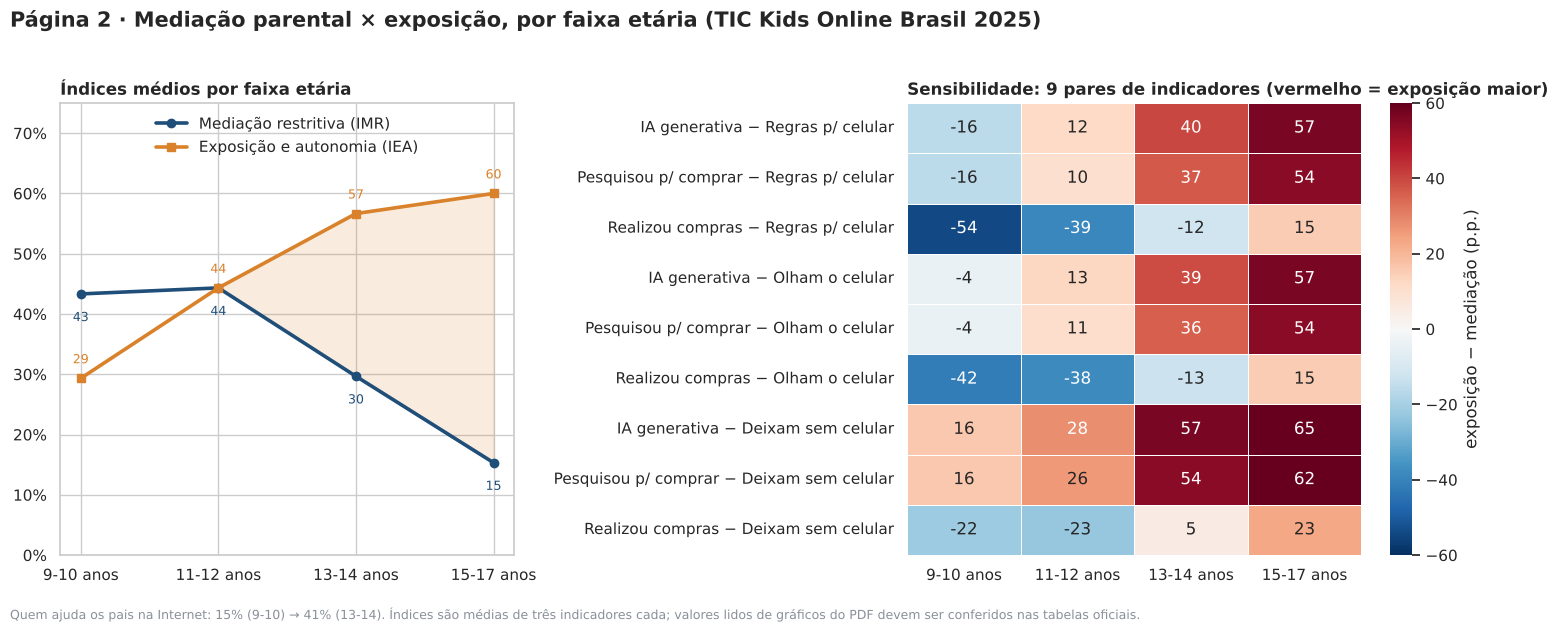

In [20]:
# ===================== Página 2 – Mediação × exposição por faixa etária ============
fig, ax = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={"width_ratios": [1, 1.25]})
a = ax[0]
x = np.arange(len(IDADES))
a.plot(x, idx.iloc[:, 0], marker="o", lw=2.6, color=COR["azul"], label="Mediação restritiva (IMR)")
a.plot(x, idx.iloc[:, 1], marker="s", lw=2.6, color=COR["laranja"], label="Exposição e autonomia (IEA)")
a.fill_between(x, idx.iloc[:, 0], idx.iloc[:, 1], where=idx.iloc[:, 1] >= idx.iloc[:, 0],
               color=COR["laranja"], alpha=.15, interpolate=True)
for i, (m_, e_) in enumerate(zip(idx.iloc[:, 0], idx.iloc[:, 1])):
    a.text(i, m_ - 4.5, f"{m_:.0f}", ha="center", color=COR["azul"], fontsize=9)
    a.text(i, e_ + 2.5, f"{e_:.0f}", ha="center", color=COR["laranja"], fontsize=9)
a.set_xticks(x); a.set_xticklabels([f"{i} anos" for i in IDADES]); a.set_ylim(0, 75)
a.yaxis.set_major_formatter(mt.FuncFormatter(pct)); a.legend(loc="upper center", ncol=1, frameon=False)
a.set_title("Índices médios por faixa etária", loc="left", fontweight="bold")

b = ax[1]
sh = sens.drop(columns="1ª faixa em que exposição > mediação")
sns.heatmap(sh, annot=True, fmt=".0f", cmap="RdBu_r", center=0, vmin=-60, vmax=60, linewidths=.5,
            cbar_kws={"label": "exposição − mediação (p.p.)"}, ax=b)
b.set_xticklabels([f"{i} anos" for i in IDADES], rotation=0)
b.set_title("Sensibilidade: 9 pares de indicadores (vermelho = exposição maior)", loc="left", fontweight="bold")
b.set_ylabel("")

fig.suptitle("Página 2 · Mediação parental × exposição, por faixa etária (TIC Kids Online Brasil 2025)",
             x=.01, ha="left", fontsize=15, fontweight="bold", y=1.02)
aj = larga.loc["Ajuda os pais a fazer algo na Internet"]
fig.text(.01, -.03, f"Quem ajuda os pais na Internet: {aj['9-10']:.0f}% (9-10) → {aj['13-14']:.0f}% (13-14). "
         "Índices são médias de três indicadores cada; valores lidos de gráficos do PDF devem ser conferidos nas tabelas oficiais.",
         fontsize=9, color=COR["cinza"])
fig.tight_layout(); fig.savefig(DASH / "02_mediacao_x_exposicao.png", dpi=150, bbox_inches="tight"); plt.show()

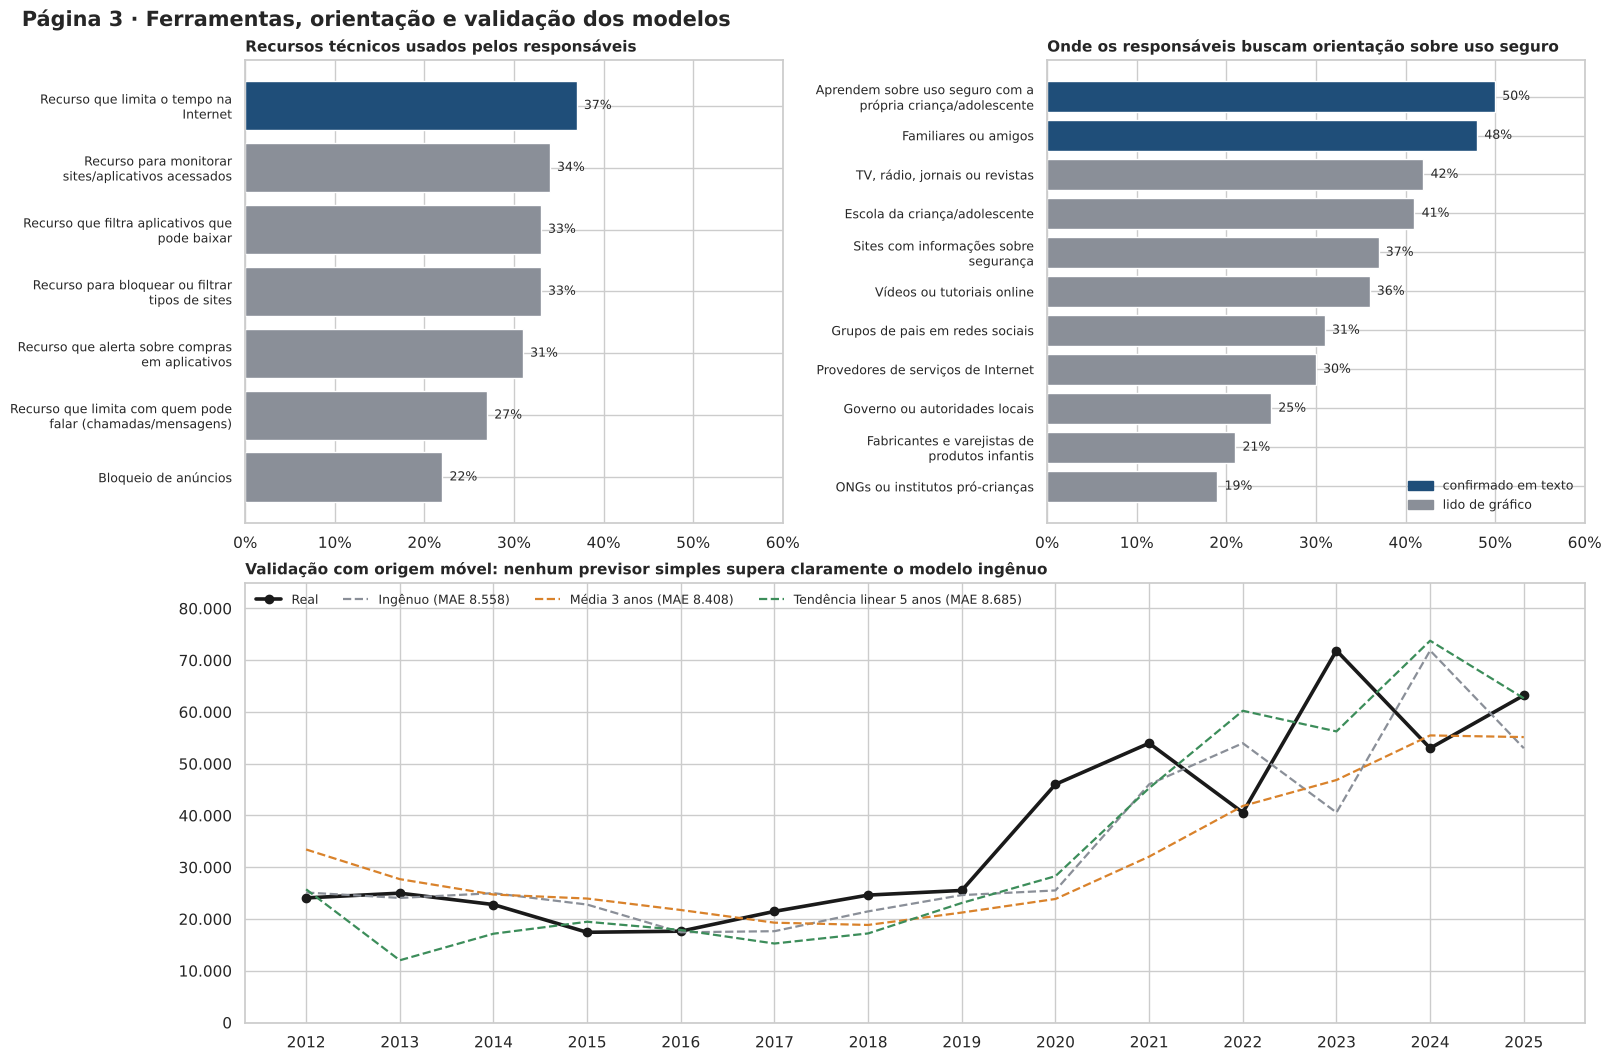

In [21]:
# ===================== Página 3 – Ferramentas, orientação e validação ==============
import textwrap
from matplotlib.patches import Patch
fig = plt.figure(figsize=(16, 10.5), constrained_layout=True)
gs = fig.add_gridspec(2, 2, height_ratios=[1, 0.95])
cores = {"confirmado_texto": COR["azul"], "leitura_grafico": COR["cinza"]}

def barras(a, bloco, titulo):
    d = tot[tot.bloco == bloco].sort_values("valor_pct")
    rot = [textwrap.fill(x, 34) for x in d.indicador]
    a.barh(rot, d.valor_pct, color=d.confianca.map(cores))
    for y_, v_ in enumerate(d.valor_pct): a.text(v_ + .8, y_, f"{v_}%", va="center", fontsize=9)
    a.set_xlim(0, 60); a.xaxis.set_major_formatter(mt.FuncFormatter(pct))
    a.tick_params(axis="y", labelsize=9)
    a.set_title(titulo, loc="left", fontweight="bold", fontsize=11)
    return a

a1 = barras(fig.add_subplot(gs[0, 0]), "mediacao_tecnica", "Recursos técnicos usados pelos responsáveis")
a2 = barras(fig.add_subplot(gs[0, 1]), "fonte_orientacao", "Onde os responsáveis buscam orientação sobre uso seguro")
a2.legend(handles=[Patch(color=COR["azul"], label="confirmado em texto"), Patch(color=COR["cinza"], label="lido de gráfico")],
          loc="lower right", frameon=False, fontsize=9)

c = fig.add_subplot(gs[1, :])
c.plot(bt.index, bt.real, color="k", lw=2.6, marker="o", label="Real")
c.plot(bt.index, bt.ingenuo, color=COR["cinza"], lw=1.6, ls="--", label=f"Ingênuo (MAE {milhar(aval.loc['ingenuo','MAE'])})")
c.plot(bt.index, bt.media3, color=COR["laranja"], lw=1.6, ls="--", label=f"Média 3 anos (MAE {milhar(aval.loc['media3','MAE'])})")
c.plot(bt.index, bt.tendencia5, color=COR["verde"], lw=1.6, ls="--", label=f"Tendência linear 5 anos (MAE {milhar(aval.loc['tendencia5','MAE'])})")
c.yaxis.set_major_formatter(mt.FuncFormatter(milhar)); c.set_xticks(bt.index); c.set_ylim(0, 85000)
c.set_title("Validação com origem móvel: nenhum previsor simples supera claramente o modelo ingênuo", loc="left", fontweight="bold", fontsize=11)
c.legend(frameon=False, ncol=4, loc="upper left", fontsize=9)

fig.suptitle("Página 3 · Ferramentas, orientação e validação dos modelos", x=.01, ha="left", fontsize=15, fontweight="bold")
fig.savefig(DASH / "03_ferramentas_e_validacao.png", dpi=150); plt.show()

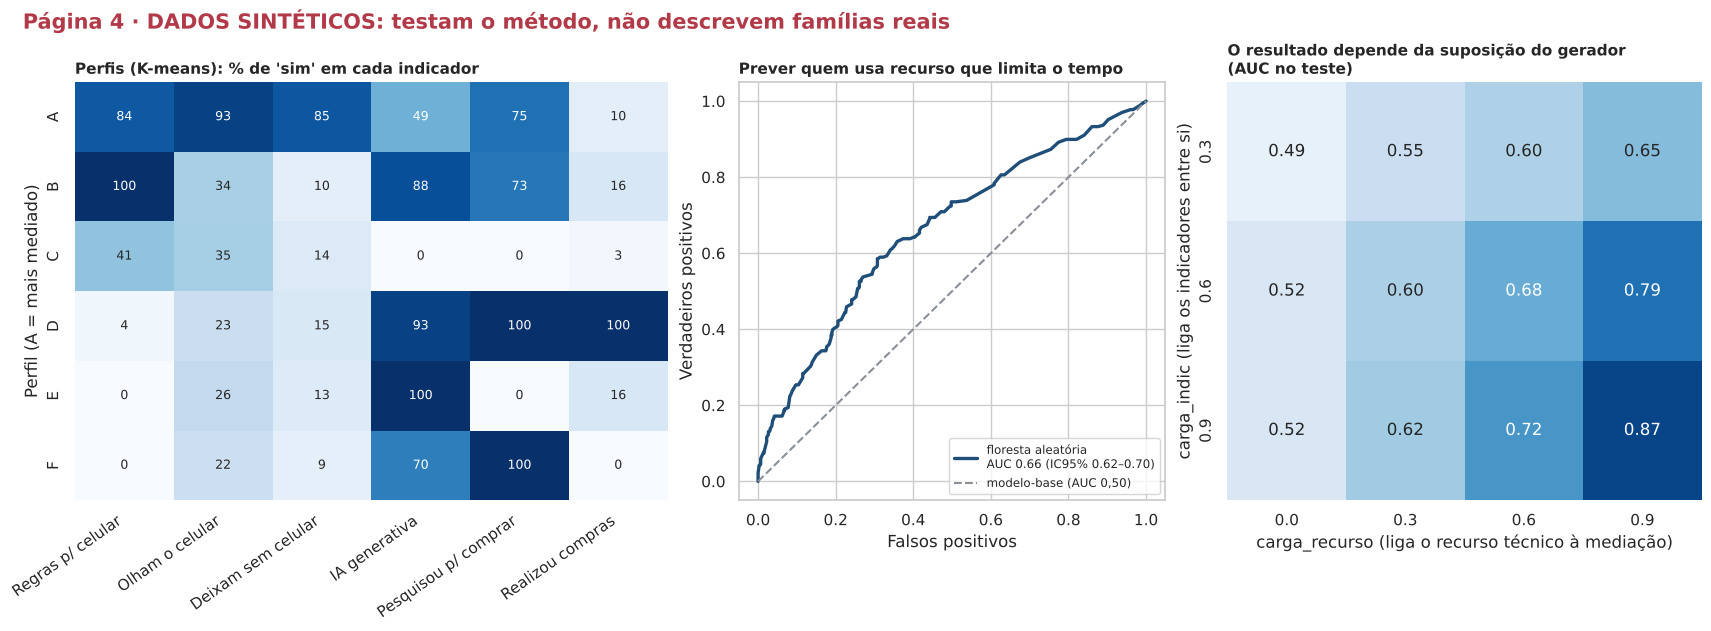

In [22]:
# ===================== Página 4 – Perfis, predição e sensibilidade (DADOS SINTÉTICOS) =============
fig, ax = plt.subplots(1, 3, figsize=(17, 6.2), gridspec_kw={"width_ratios": [1.25, 0.9, 1]}, constrained_layout=True)

a = ax[0]
sns.heatmap(ind_perfil.round(0), ax=a, cmap="Blues", vmin=0, vmax=100, annot=True, fmt=".0f", cbar=False, annot_kws={"size": 9})
a.set_title("Perfis (K-means): % de 'sim' em cada indicador", loc="left", fontsize=11, fontweight="bold")
a.set_ylabel("Perfil (A = mais mediado)"); a.set_xlabel(""); a.tick_params(axis="x", rotation=35)
for lab in a.get_xticklabels(): lab.set_ha("right")

a = ax[1]
fpr, tpr, _ = roc_curve(yte, p_te)
a.plot(fpr, tpr, color=COR["azul"], lw=2.4, label=f"{escolhido}\nAUC {auc_te:.2f} (IC95% {ic_lo:.2f}–{ic_hi:.2f})")
a.plot([0, 1], [0, 1], color=COR["cinza"], ls="--", label="modelo-base (AUC 0,50)")
a.set_xlabel("Falsos positivos"); a.set_ylabel("Verdadeiros positivos")
a.set_title("Prever quem usa recurso que limita o tempo", loc="left", fontsize=11, fontweight="bold")
a.legend(loc="lower right", fontsize=8.5)

a = ax[2]
sns.heatmap(tab_auc, ax=a, cmap="Blues", vmin=0.45, vmax=0.9, annot=True, fmt=".2f", cbar=False)
a.set_title("O resultado depende da suposição do gerador\n(AUC no teste)", loc="left", fontsize=11, fontweight="bold")
a.set_xlabel("carga_recurso (liga o recurso técnico à mediação)"); a.set_ylabel("carga_indic (liga os indicadores entre si)")

fig.suptitle("Página 4 · DADOS SINTÉTICOS: testam o método, não descrevem famílias reais", x=.01, ha="left",
             fontsize=15, fontweight="bold", color=COR["vermelho"])
fig.savefig(DASH / "04_perfis_e_modelo_sintetico.png", dpi=150); plt.show()

### 6.1 Plano de implementação (arquitetura) e como manter o projeto

A ordem é: `dados/` (tabelas reais e sintéticas), `scripts/` (geram os dados e o notebook), `notebooks/` (as 6 fases), `dashboard/` (4 páginas) e `README.md`.
Tudo fica no GitHub e dá para reproduzir com quatro comandos.

1. **Atualização anual.** A SaferNet publica os indicadores no Dia da Internet Segura (fevereiro) e o Cetic.br divulga o TIC Kids
   Online em outubro. Basta ajustar o `scripts/criar_dados.py` e rodar o notebook de novo (o gerador sintético lê as tabelas atualizadas).
2. **Conferir as linhas `leitura_grafico`** contra as tabelas oficiais antes de cada entrega.
3. **Microdados.** Quando tivermos acesso aos microdados do TIC Kids, vamos trocar os sintéticos pelos reais e rodar a P3 de novo (K-means de perfis de mediação e
   classificação de quem não usa recurso técnico). Comparar as métricas dos dois mostra o quanto as nossas suposições valiam.
4. **Ligação com o TCC.** A matriz de avaliação das cinco plataformas (usabilidade, IA, detecção de risco, conformidade) pode entrar como
   terceira tabela. A hipótese para o capítulo de resultados é que as ferramentas precisam **se adaptar à idade**, porque a mediação
   restritiva cai enquanto a autonomia cresce, e o **diálogo** conta tanto quanto o bloqueio.

### 6.2 Plano de monitoramento (quando o trabalho fica desatualizado)

| Quando | O que fazer |
|---|---|
| Sai uma nova edição da SaferNet (fevereiro) | Atualizar a série, refazer a validação com origem móvel e ver se o MAE do P1 muda a conclusão |
| Sai uma nova edição do TIC Kids (outubro) | Atualizar as tabelas e gerar os dados sintéticos de novo. A checagem S3 e a integração da Fase 3 falham se os percentuais não baterem |
| Chegam os microdados reais | Aposentar os sintéticos, rodar a P3 de novo e comparar AUC e silhueta com os valores sintéticos |
| Conferimos as linhas `leitura_grafico` | Corrigir o CSV, rodar de novo e ver se a conclusão de P2 se mantém |

### 6.3 Relatório e apresentação final

Entregamos o README (resultados e limites), este notebook já executado e o dashboard de 4 páginas. Na apresentação vamos seguir a ordem das fases: problema,
dados e qualidade, índices, modelos e testes, critérios atingidos e não atingidos, e o que fazer a seguir.

### 6.4 Revisão do projeto (lições aprendidas)

- Definir os critérios de sucesso antes de modelar nos deixou assumir dois resultados negativos sem mexer no critério.
- Preparar os dados e decidir sobre os dados sintéticos tomou mais tempo que a modelagem, como o guia avisa.
- Dado sintético serve para treinar e testar o método. A análise de sensibilidade mostrou que o resultado da P3 muda bastante conforme a suposição do gerador,
  então nunca vamos apresentar esses dados como achado sobre famílias reais.
- Voltar às fases anteriores faz parte do ciclo: a Fase 5 nos devolveu às Fases 2 e 3 (microdados e conferência dos gráficos).

### Referências das fontes de dados

- SAFERNET BRASIL. *Indicadores Denúncias 2025.* Disponível em: arquivos.safernet.org.br/pdfs/INDICADORES-DenunciasSaferNet2025.pdf.
- CETIC.BR/NIC.BR. *TIC Kids Online Brasil 2025 – Principais Resultados.* São Paulo, 22 out. 2025. Disponível em: cetic.br/media/analises/tic_kids_online_brasil_2025_principais_resultados.pdf.
- FUNDAÇÃO TELEFÔNICA VIVO. *Nota técnica: TIC Kids Online Brasil 2025.* 31 out. 2025.
- CHAPMAN, P. et al. *CRISP-DM 1.0: Step-by-step data mining guide.* 2000.
- VALÉRIA, K. *Guia Prático: o modelo CRISP-DM.* Ciência de Dados e Aprendizagem de Máquina, UDF (material da disciplina).